In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving Online Retail.xlsx to Online Retail.xlsx
Uploaded files: ['Online Retail.xlsx']


In [3]:
import zipfile
import io
import os

excel_files = []

for filename, content in uploaded.items():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            print("Files inside ZIP:", z.namelist())

            for member in z.namelist():
                if member.lower().endswith((".xlsx", ".xls")):
                    output_path = os.path.basename(member)
                    with z.open(member) as source, open(output_path, "wb") as target:
                        target.write(source.read())
                    excel_files.append(output_path)

    elif filename.lower().endswith((".xlsx", ".xls")):
        excel_files.append(filename)

if not excel_files:
    raise ValueError(
        "No Excel file found. Upload the dataset ZIP or Excel file."
    )

print("Excel files ready:", excel_files)

Excel files ready: ['Online Retail.xlsx']


In [4]:
file_path = excel_files[0]

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("DATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nSUMMARY STATISTICS")
display(df.describe(include="all").T)

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

MISSING VALUES


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



DUPLICATE ROWS
5268

SUMMARY STATISTICS


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
retail = df.copy()

# Standardise column names and text fields
retail.columns = retail.columns.str.strip()

retail["InvoiceNo"] = retail["InvoiceNo"].astype("string").str.strip()
retail["StockCode"] = retail["StockCode"].astype("string").str.strip()
retail["Description"] = retail["Description"].astype("string").str.strip()
retail["CustomerID"] = retail["CustomerID"].astype("string").str.strip()

# Convert numeric and date columns
retail["Quantity"] = pd.to_numeric(retail["Quantity"], errors="coerce")
retail["UnitPrice"] = pd.to_numeric(retail["UnitPrice"], errors="coerce")
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"], errors="coerce"
)

# Identify cancellation invoices before filtering
retail["IsCancellation"] = (
    retail["InvoiceNo"].str.upper().str.startswith("C", na=False)
)

# Record quality metrics before cleaning
quality_report = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Exact duplicate rows",
        "Missing customer IDs",
        "Missing descriptions",
        "Cancellation invoice rows",
        "Rows with non-positive quantity",
        "Rows with non-positive unit price"
    ],
    "Count": [
        len(retail),
        int(retail.duplicated().sum()),
        int(retail["CustomerID"].isna().sum()),
        int(retail["Description"].isna().sum()),
        int(retail["IsCancellation"].sum()),
        int((retail["Quantity"] <= 0).sum()),
        int((retail["UnitPrice"] <= 0).sum())
    ]
})

display(quality_report)

,Metric,Count
0,Original rows,541909
1,Exact duplicate rows,5268
2,Missing customer IDs,135080
3,Missing descriptions,1454
4,Cancellation invoice rows,9288
5,Rows with non-positive quantity,10624
6,Rows with non-positive unit price,2517


In [7]:
retail = retail.drop_duplicates().copy()

retail = retail.dropna(
    subset=[
        "InvoiceNo",
        "StockCode",
        "InvoiceDate",
        "Quantity",
        "UnitPrice"
    ]
).copy()

sales = retail.loc[
    (~retail["IsCancellation"]) &
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["InvoiceMonth"] = sales["InvoiceDate"].dt.to_period("M").astype(str)
sales["DayOfWeek"] = sales["InvoiceDate"].dt.day_name()

print("Rows after cleaning:", len(retail))
print("Rows retained for sales analysis:", len(sales))
print("Total sales revenue (£):", round(sales["Revenue"].sum(), 2))
print("Unique invoices:", sales["InvoiceNo"].nunique())
print("Unique products:", sales["StockCode"].nunique())
print("Identified customers:", sales["CustomerID"].nunique())

sales.head()

Rows after cleaning: 536641
Rows retained for sales analysis: 524878
Total sales revenue (£): 10642110.8
Unique invoices: 19960
Unique products: 3922
Identified customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,Revenue,InvoiceMonth,DayOfWeek
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,2010-12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,2010-12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12,Wednesday


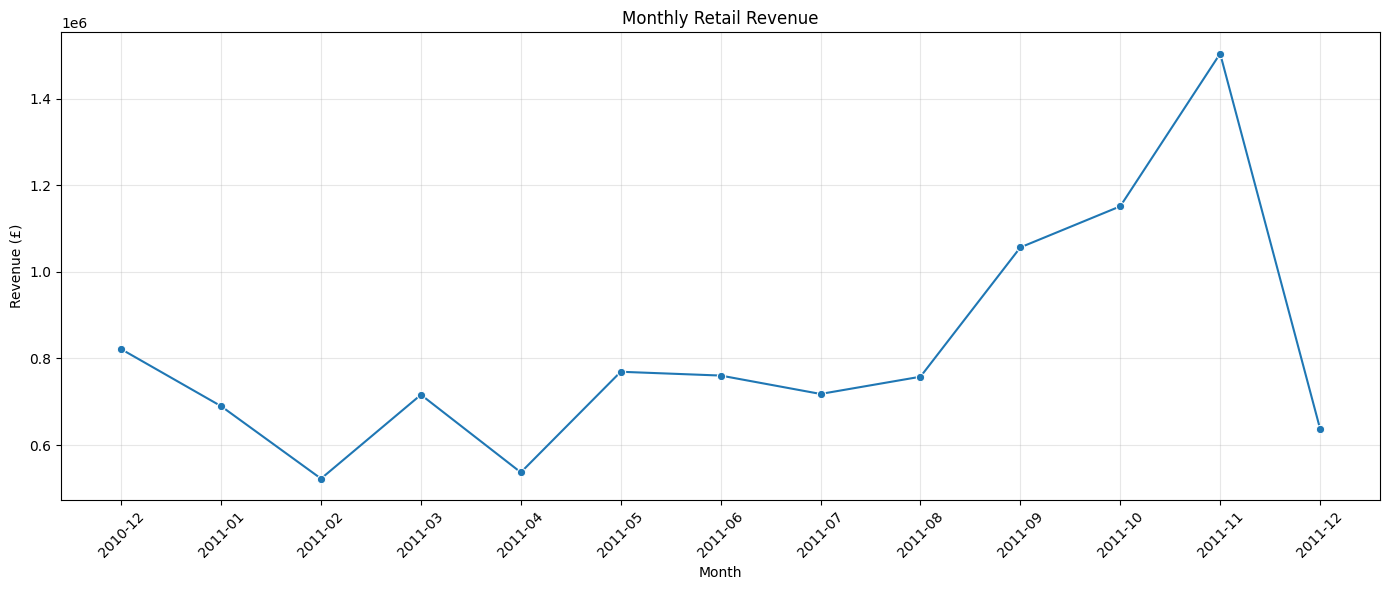

,InvoiceMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


In [8]:
monthly_revenue = (
    sales.groupby("InvoiceMonth", as_index=False)["Revenue"]
    .sum()
    .sort_values("InvoiceMonth")
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_revenue,
    x="InvoiceMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_revenue)

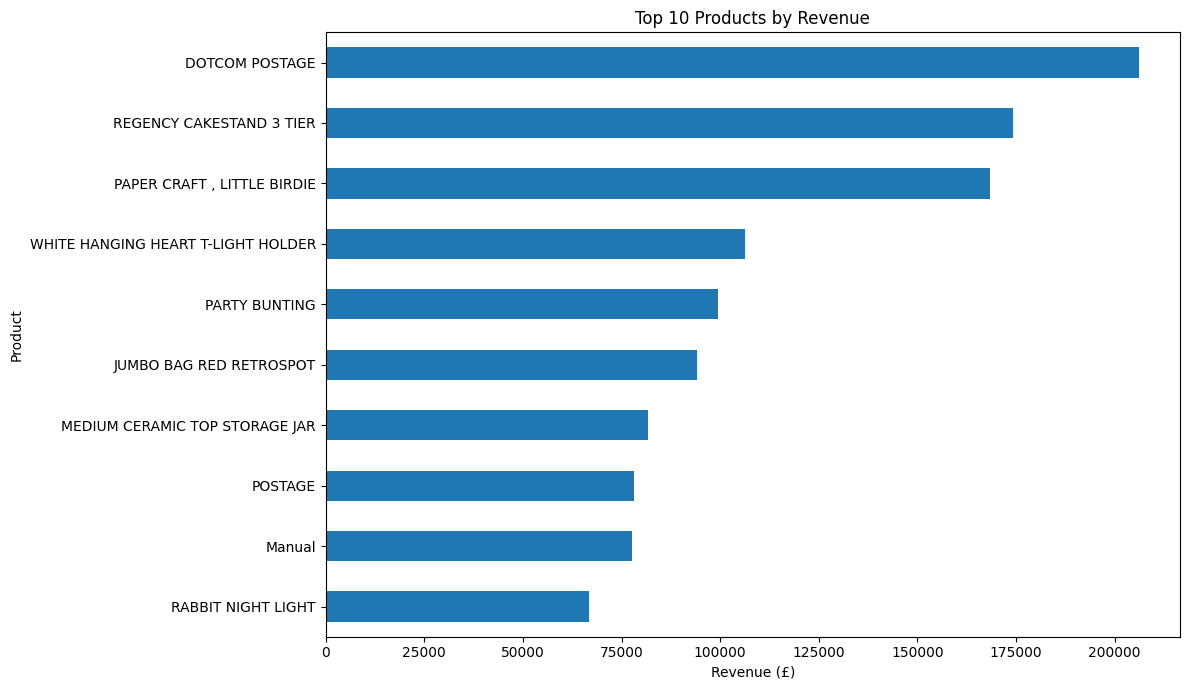

,Revenue (£)
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [9]:
top_products = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(top_products.sort_values(ascending=False).to_frame("Revenue (£)"))

,Country,Revenue,Orders,Units_Sold
36,United Kingdom,9001744.094,18019,4646906
24,Netherlands,285446.340,94,200361
10,EIRE,283140.520,288,147007
14,Germany,228678.400,457,119154
13,France,209625.370,392,112060
0,Australia,138453.810,57,83891
31,Spain,61558.560,90,27933
33,Switzerland,57067.600,54,30617
3,Belgium,41196.340,98,23237
32,Sweden,38367.830,36,36078


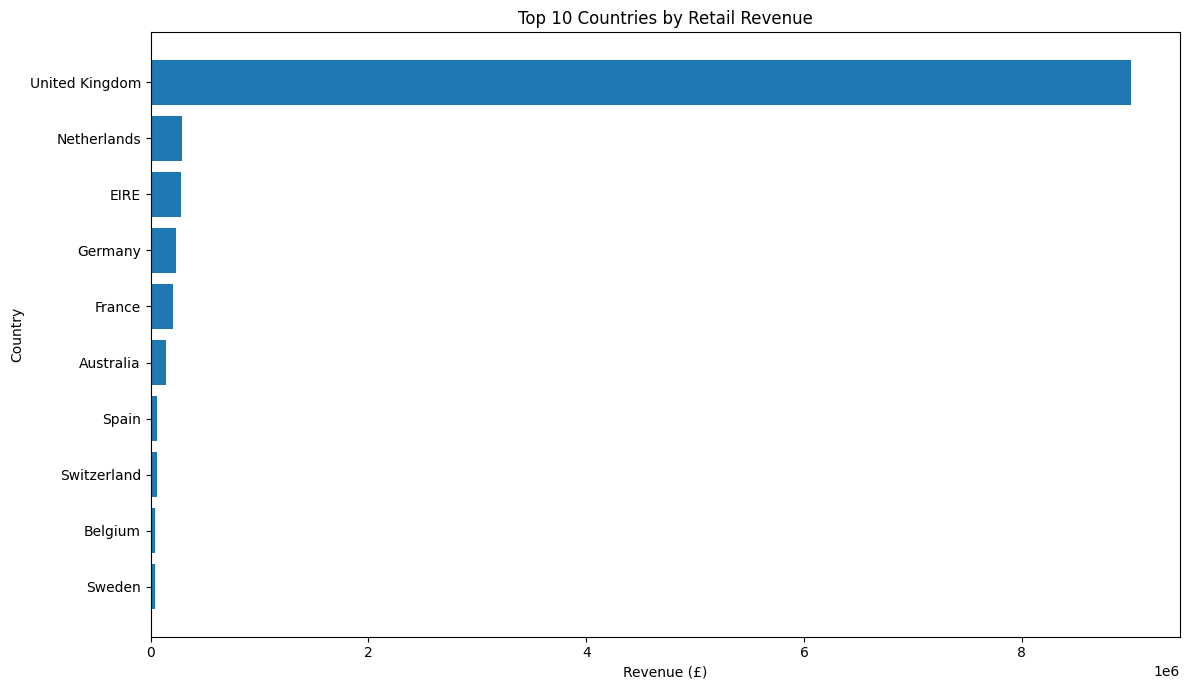

In [10]:
country_sales = (
    sales.groupby("Country", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

display(country_sales.head(10))

plt.figure(figsize=(12, 7))
plot_data = country_sales.head(10).sort_values("Revenue")

plt.barh(plot_data["Country"], plot_data["Revenue"])
plt.title("Top 10 Countries by Retail Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Total orders: 19960
Mean order value (£): 533.17
Median order value (£): 303.3


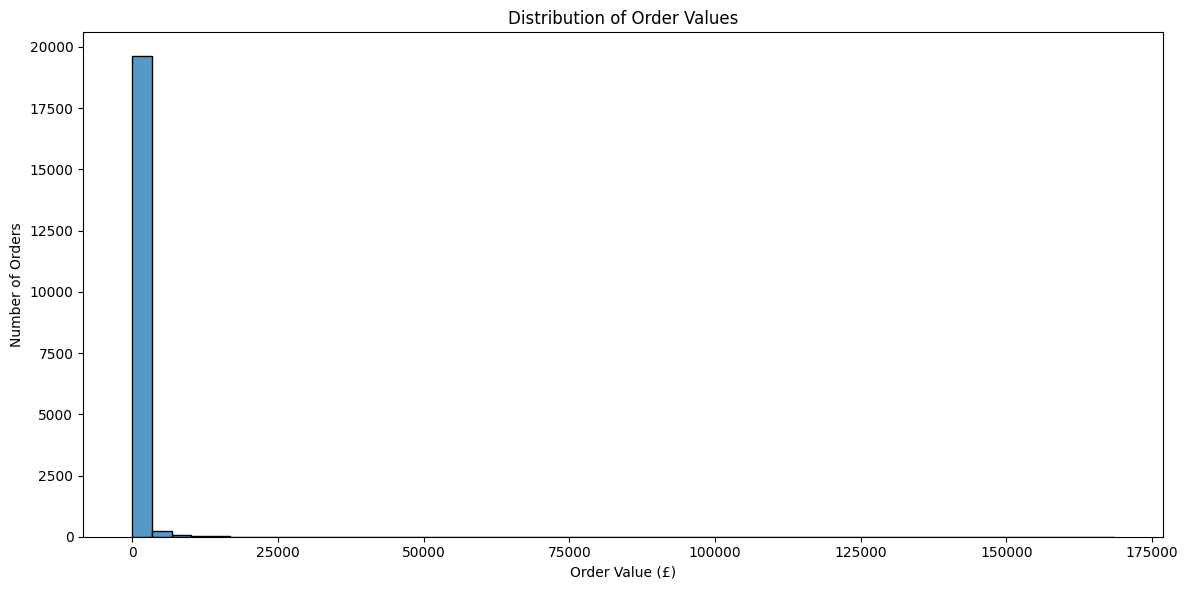

In [11]:
orders = (
    sales.groupby("InvoiceNo", as_index=False)
    .agg(
        OrderValue=("Revenue", "sum"),
        Units=("Quantity", "sum"),
        CustomerID=("CustomerID", "first"),
        Country=("Country", "first")
    )
)

print("Total orders:", len(orders))
print("Mean order value (£):", round(orders["OrderValue"].mean(), 2))
print("Median order value (£):", round(orders["OrderValue"].median(), 2))

plt.figure(figsize=(12, 6))
sns.histplot(orders["OrderValue"], bins=50)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value (£)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [12]:
kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue (£)",
        "Units Sold",
        "Unique Orders",
        "Unique Products",
        "Identified Customers",
        "Average Order Value (£)",
        "Median Order Value (£)"
    ],
    "Value": [
        sales["Revenue"].sum(),
        sales["Quantity"].sum(),
        sales["InvoiceNo"].nunique(),
        sales["StockCode"].nunique(),
        sales["CustomerID"].nunique(),
        orders["OrderValue"].mean(),
        orders["OrderValue"].median()
    ]
})

display(kpis.round(2))

,Metric,Value
0,Total Revenue (£),10642110.80
1,Units Sold,5572420.00
2,Unique Orders,19960.00
3,Unique Products,3922.00
4,Identified Customers,4338.00
5,Average Order Value (£),533.17
6,Median Order Value (£),303.30


In [13]:
import os

os.makedirs("outputs", exist_ok=True)

monthly_revenue.to_csv("outputs/monthly_revenue.csv", index=False)
country_sales.to_csv("outputs/country_sales.csv", index=False)
top_products.to_csv("outputs/top_products.csv")
orders.to_csv("outputs/order_summary.csv", index=False)
kpis.to_csv("outputs/kpi_summary.csv", index=False)

sales.to_csv("cleaned_retail_sales.csv", index=False)

print("All outputs exported successfully!")

All outputs exported successfully!


In [14]:
files.download("cleaned_retail_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
%pip install -q duckdb

In [16]:
import duckdb

con = duckdb.connect("retail_analytics.duckdb")

con.register("sales_df", sales)

con.execute("""
    CREATE OR REPLACE TABLE retail_sales AS
    SELECT * FROM sales_df
""")

print("SQL table created successfully!")

print(
    con.execute("SELECT COUNT(*) FROM retail_sales").fetchdf()
)

SQL table created successfully!
   count_star()
0        524878


In [17]:
con.execute("""
    SELECT
        ROUND(SUM(Revenue), 2) AS total_revenue,
        SUM(Quantity) AS total_units_sold,
        COUNT(DISTINCT InvoiceNo) AS total_orders,
        COUNT(DISTINCT StockCode) AS unique_products,
        COUNT(DISTINCT CustomerID) AS identified_customers
    FROM retail_sales
""").fetchdf()

,total_revenue,total_units_sold,total_orders,unique_products,identified_customers
0,10642110.8,5572420.0,19960,3922,4338


In [18]:
con.execute("""
    SELECT
        InvoiceMonth,
        ROUND(SUM(Revenue), 2) AS monthly_revenue
    FROM retail_sales
    GROUP BY InvoiceMonth
    ORDER BY monthly_revenue DESC
""").fetchdf()

,InvoiceMonth,monthly_revenue
0,2011-11,1503866.78
1,2011-10,1151263.73
2,2011-09,1056435.19
3,2010-12,821452.73
4,2011-05,769296.61
5,2011-06,760547.01
6,2011-08,757841.38
7,2011-07,718076.12
8,2011-03,716215.26
9,2011-01,689811.61


In [19]:
con.execute("""
    SELECT
        Description,
        ROUND(SUM(Revenue), 2) AS total_revenue,
        SUM(Quantity) AS units_sold
    FROM retail_sales
    GROUP BY Description
    ORDER BY total_revenue DESC
    LIMIT 10
""").fetchdf()

,Description,total_revenue,units_sold
0,DOTCOM POSTAGE,206248.77,706.0
1,REGENCY CAKESTAND 3 TIER,174156.54,13851.0
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995.0
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872.0
4,PARTY BUNTING,99445.23,18283.0
5,JUMBO BAG RED RETROSPOT,94159.81,48371.0
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033.0
7,POSTAGE,78101.88,3150.0
8,Manual,77752.82,6985.0
9,RABBIT NIGHT LIGHT,66870.03,30739.0


In [20]:
con.execute("""
    SELECT
        Country,
        ROUND(SUM(Revenue), 2) AS total_revenue,
        COUNT(DISTINCT InvoiceNo) AS total_orders
    FROM retail_sales
    GROUP BY Country
    ORDER BY total_revenue DESC
""").fetchdf()

,Country,total_revenue,total_orders
0,United Kingdom,9001744.09,18019
1,Netherlands,285446.34,94
2,EIRE,283140.52,288
3,Germany,228678.40,457
4,France,209625.37,392
5,Australia,138453.81,57
6,Spain,61558.56,90
7,Switzerland,57067.60,54
8,Belgium,41196.34,98
9,Sweden,38367.83,36


In [21]:
con.execute("""
    WITH order_totals AS (
        SELECT
            InvoiceNo,
            SUM(Revenue) AS order_value
        FROM retail_sales
        GROUP BY InvoiceNo
    )
    SELECT
        ROUND(AVG(order_value), 2) AS average_order_value,
        ROUND(MEDIAN(order_value), 2) AS median_order_value
    FROM order_totals
""").fetchdf()

,average_order_value,median_order_value
0,533.17,303.3


In [22]:
con.execute("""
    WITH country_sales AS (
        SELECT
            Country,
            SUM(Revenue) AS country_revenue
        FROM retail_sales
        GROUP BY Country
    )
    SELECT
        Country,
        ROUND(country_revenue, 2) AS revenue,
        ROUND(
            100.0 * country_revenue
            / SUM(country_revenue) OVER (),
            2
        ) AS revenue_share_pct
    FROM country_sales
    ORDER BY revenue DESC
""").fetchdf()

,Country,revenue,revenue_share_pct
0,United Kingdom,9001744.09,84.59
1,Netherlands,285446.34,2.68
2,EIRE,283140.52,2.66
3,Germany,228678.40,2.15
4,France,209625.37,1.97
5,Australia,138453.81,1.30
6,Spain,61558.56,0.58
7,Switzerland,57067.60,0.54
8,Belgium,41196.34,0.39
9,Sweden,38367.83,0.36


In [23]:
con.execute("""
    WITH monthly_sales AS (
        SELECT
            InvoiceMonth,
            SUM(Revenue) AS revenue
        FROM retail_sales
        GROUP BY InvoiceMonth
    ),
    comparison AS (
        SELECT
            InvoiceMonth,
            revenue,
            LAG(revenue) OVER (ORDER BY InvoiceMonth) AS previous_revenue
        FROM monthly_sales
    )
    SELECT
        InvoiceMonth,
        ROUND(revenue, 2) AS revenue,
        ROUND(previous_revenue, 2) AS previous_revenue,
        ROUND(
            100.0 * (revenue - previous_revenue)
            / NULLIF(previous_revenue, 0),
            2
        ) AS growth_pct
    FROM comparison
    ORDER BY InvoiceMonth
""").fetchdf()

,InvoiceMonth,revenue,previous_revenue,growth_pct
0,2010-12,821452.73,NaN,NaN
1,2011-01,689811.61,821452.73,-16.03
2,2011-02,522545.56,689811.61,-24.25
3,2011-03,716215.26,522545.56,37.06
4,2011-04,536968.49,716215.26,-25.03
5,2011-05,769296.61,536968.49,43.27
6,2011-06,760547.01,769296.61,-1.14
7,2011-07,718076.12,760547.01,-5.58
8,2011-08,757841.38,718076.12,5.54
9,2011-09,1056435.19,757841.38,39.40


In [24]:
con.execute("""
    SELECT
        CustomerID,
        ROUND(SUM(Revenue), 2) AS customer_revenue,
        COUNT(DISTINCT InvoiceNo) AS order_count
    FROM retail_sales
    WHERE CustomerID IS NOT NULL
    GROUP BY CustomerID
    ORDER BY customer_revenue DESC
    LIMIT 10
""").fetchdf()

,CustomerID,customer_revenue,order_count
0,14646.0,280206.02,73
1,18102.0,259657.30,60
2,17450.0,194390.79,46
3,16446.0,168472.50,2
4,14911.0,143711.17,201
5,12415.0,124914.53,21
6,14156.0,117210.08,55
7,17511.0,91062.38,31
8,16029.0,80850.84,63
9,12346.0,77183.60,1


In [25]:
con.execute("""
    SELECT
        StockCode,
        Description,
        SUM(Quantity) AS units_sold
    FROM retail_sales
    GROUP BY StockCode, Description
    ORDER BY units_sold DESC
    LIMIT 10
""").fetchdf()

,StockCode,Description,units_sold
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995.0
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033.0
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951.0
3,85099B,JUMBO BAG RED RETROSPOT,48371.0
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580.0
5,22197,POPCORN HOLDER,36749.0
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396.0
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362.0
8,23084,RABBIT NIGHT LIGHT,30739.0
9,22492,MINI PAINT SET VINTAGE,26633.0


In [26]:
con.execute("""
    SELECT
        DayOfWeek,
        ROUND(SUM(Revenue), 2) AS revenue,
        COUNT(DISTINCT InvoiceNo) AS order_count
    FROM retail_sales
    GROUP BY DayOfWeek
    ORDER BY
        CASE DayOfWeek
            WHEN 'Monday' THEN 1
            WHEN 'Tuesday' THEN 2
            WHEN 'Wednesday' THEN 3
            WHEN 'Thursday' THEN 4
            WHEN 'Friday' THEN 5
            WHEN 'Saturday' THEN 6
            WHEN 'Sunday' THEN 7
        END
""").fetchdf()

,DayOfWeek,revenue,order_count
0,Monday,1775782.07,3126
1,Tuesday,2175700.51,3554
2,Wednesday,1847074.38,3690
3,Thursday,2199292.57,4246
4,Friday,1837470.49,3140
5,Sunday,806790.78,2204


In [27]:
sql_code = r"""
-- Project: Retail Business Intelligence
-- Purpose: Analyse sales performance using SQL

-- Query 1: Overall business KPIs
SELECT
    ROUND(SUM(Revenue), 2) AS total_revenue,
    SUM(Quantity) AS total_units_sold,
    COUNT(DISTINCT InvoiceNo) AS total_orders,
    COUNT(DISTINCT StockCode) AS unique_products,
    COUNT(DISTINCT CustomerID) AS identified_customers
FROM retail_sales;

-- Query 2: Monthly revenue ranking
SELECT
    InvoiceMonth,
    ROUND(SUM(Revenue), 2) AS monthly_revenue
FROM retail_sales
GROUP BY InvoiceMonth
ORDER BY monthly_revenue DESC;

-- Query 3: Top 10 products by revenue
SELECT
    Description,
    ROUND(SUM(Revenue), 2) AS total_revenue,
    SUM(Quantity) AS units_sold
FROM retail_sales
GROUP BY Description
ORDER BY total_revenue DESC
LIMIT 10;

-- Query 4: Country performance
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS total_revenue,
    COUNT(DISTINCT InvoiceNo) AS total_orders
FROM retail_sales
GROUP BY Country
ORDER BY total_revenue DESC;

-- Query 5: Average and median order value
WITH order_totals AS (
    SELECT InvoiceNo, SUM(Revenue) AS order_value
    FROM retail_sales
    GROUP BY InvoiceNo
)
SELECT
    ROUND(AVG(order_value), 2) AS average_order_value,
    ROUND(MEDIAN(order_value), 2) AS median_order_value
FROM order_totals;

-- Query 6: Country revenue contribution
WITH country_sales AS (
    SELECT Country, SUM(Revenue) AS country_revenue
    FROM retail_sales
    GROUP BY Country
)
SELECT
    Country,
    ROUND(country_revenue, 2) AS revenue,
    ROUND(
        100.0 * country_revenue / SUM(country_revenue) OVER (),
        2
    ) AS revenue_share_pct
FROM country_sales
ORDER BY revenue DESC;

-- Query 7: Month-over-month revenue growth
WITH monthly_sales AS (
    SELECT InvoiceMonth, SUM(Revenue) AS revenue
    FROM retail_sales
    GROUP BY InvoiceMonth
),
comparison AS (
    SELECT
        InvoiceMonth,
        revenue,
        LAG(revenue) OVER (ORDER BY InvoiceMonth) AS previous_revenue
    FROM monthly_sales
)
SELECT
    InvoiceMonth,
    ROUND(revenue, 2) AS revenue,
    ROUND(previous_revenue, 2) AS previous_revenue,
    ROUND(
        100.0 * (revenue - previous_revenue)
        / NULLIF(previous_revenue, 0),
        2
    ) AS growth_pct
FROM comparison
ORDER BY InvoiceMonth;

-- Query 8: Top 10 identified customers
SELECT
    CustomerID,
    ROUND(SUM(Revenue), 2) AS customer_revenue,
    COUNT(DISTINCT InvoiceNo) AS order_count
FROM retail_sales
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID
ORDER BY customer_revenue DESC
LIMIT 10;

-- Query 9: Top products by sales volume
SELECT
    StockCode,
    Description,
    SUM(Quantity) AS units_sold
FROM retail_sales
GROUP BY StockCode, Description
ORDER BY units_sold DESC
LIMIT 10;

-- Query 10: Revenue by day of the week
SELECT
    DayOfWeek,
    ROUND(SUM(Revenue), 2) AS revenue,
    COUNT(DISTINCT InvoiceNo) AS order_count
FROM retail_sales
GROUP BY DayOfWeek
ORDER BY CASE DayOfWeek
    WHEN 'Monday' THEN 1
    WHEN 'Tuesday' THEN 2
    WHEN 'Wednesday' THEN 3
    WHEN 'Thursday' THEN 4
    WHEN 'Friday' THEN 5
    WHEN 'Saturday' THEN 6
    WHEN 'Sunday' THEN 7
END;
"""

print("SQL script prepared.")
print("Number of query labels:", sql_code.count("-- Query"))

SQL script prepared.
Number of query labels: 10


In [28]:
from google.colab import files

with open("analysis_queries.sql", "w", encoding="utf-8") as f:
    f.write(sql_code)

files.download("analysis_queries.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
# 1. Monthly revenue performance
best_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmax()
]

worst_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmin()
]

# 2. Top products
product_revenue = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# 3. Country performance
country_revenue = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# 4. Order behaviour
mean_order_value = orders["OrderValue"].mean()
median_order_value = orders["OrderValue"].median()

# 5. Customer revenue concentration
customer_sales = (
    sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

top_10_customer_share = (
    customer_sales.head(10).sum()
    / customer_sales.sum() * 100
)

# Display results
print("MONTHLY PERFORMANCE")
print("Highest revenue month:", best_month["InvoiceMonth"])
print("Highest monthly revenue (£):", round(best_month["Revenue"], 2))
print("Lowest revenue month:", worst_month["InvoiceMonth"])
print("Lowest monthly revenue (£):", round(worst_month["Revenue"], 2))

print("\nPRODUCT PERFORMANCE")
print(product_revenue.head(5).round(2))

print("\nCOUNTRY PERFORMANCE")
print(country_revenue.head(5).round(2))

print("\nORDER BEHAVIOUR")
print("Mean order value (£):", round(mean_order_value, 2))
print("Median order value (£):", round(median_order_value, 2))

print("\nCUSTOMER CONCENTRATION")
print("Top 10 customers' share of identified-customer revenue (%):",
      round(top_10_customer_share, 2))

MONTHLY PERFORMANCE
Highest revenue month: 2011-11
Highest monthly revenue (£): 1503866.78
Lowest revenue month: 2011-02
Lowest monthly revenue (£): 522545.56

PRODUCT PERFORMANCE
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
Name: Revenue, dtype: float64

COUNTRY PERFORMANCE
Country
United Kingdom    9001744.09
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Name: Revenue, dtype: float64

ORDER BEHAVIOUR
Mean order value (£): 533.17
Median order value (£): 303.3

CUSTOMER CONCENTRATION
Top 10 customers' share of identified-customer revenue (%): 17.3


In [30]:
from pathlib import Path

report_dir = Path("reports")
report_dir.mkdir(exist_ok=True)

report = f"""
# Retail Business Intelligence — Findings Report

## 1. Project Objective
Analyse historical online retail transactions to understand sales
performance, product contribution, geographic trends and customer behaviour.

## 2. Revenue Performance
Highest-revenue month: {best_month['InvoiceMonth']}
Revenue: £{best_month['Revenue']:,.2f}

Lowest-revenue month: {worst_month['InvoiceMonth']}
Revenue: £{worst_month['Revenue']:,.2f}

## 3. Product Performance
Top five products by revenue:
{product_revenue.head(5).to_string()}

## 4. Geographic Performance
Top five countries by revenue:
{country_revenue.head(5).to_string()}

## 5. Order Behaviour
Mean order value: £{mean_order_value:,.2f}
Median order value: £{median_order_value:,.2f}

## 6. Customer Concentration
The top 10 identified customers account for
{top_10_customer_share:.2f}% of revenue from identified customers.

## 7. Limitations
- The dataset covers historical transactions from 2010–2011.
- Some transactions do not have customer identifiers.
- Cancellation invoices and invalid sale lines were excluded
  from the main sales analysis.
- Revenue is quantity multiplied by unit price, not verified profit.
- Observational patterns do not establish causal relationships.

## 8. Recommendations
Recommendations must be written after reviewing the actual results.
"""

with open(report_dir / "business_findings.md", "w", encoding="utf-8") as f:
    f.write(report)

print(report)
print("\nReport saved to reports/business_findings.md")


# Retail Business Intelligence — Findings Report

## 1. Project Objective
Analyse historical online retail transactions to understand sales
performance, product contribution, geographic trends and customer behaviour.

## 2. Revenue Performance
Highest-revenue month: 2011-11
Revenue: £1,503,866.78

Lowest-revenue month: 2011-02
Revenue: £522,545.56

## 3. Product Performance
Top five products by revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23

## 4. Geographic Performance
Top five countries by revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370

## 5. Order Behaviour
Mean order value: £533.17
Median order value: £303.30

## 6. Customer Concentration
The top 10 ide

In [31]:
import os
import zipfile

# Make sure the output directory exists
os.makedirs("outputs", exist_ok=True)

# Save key tables
monthly_revenue.to_csv("outputs/monthly_revenue.csv", index=False)
country_revenue.rename("Revenue").to_csv("outputs/country_revenue.csv")
product_revenue.head(10).rename("Revenue").to_csv("outputs/top_products.csv")
orders.to_csv("outputs/order_summary.csv", index=False)

with zipfile.ZipFile("retail_project_outputs.zip", "w",
                     zipfile.ZIP_DEFLATED) as z:
    for folder in ["outputs", "reports"]:
        for root, _, filenames in os.walk(folder):
            for filename in filenames:
                filepath = os.path.join(root, filename)
                z.write(filepath)

print("Project outputs packaged successfully.")

Project outputs packaged successfully.


In [32]:
from google.colab import files
files.download("retail_project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>